# Metadata-only model comparison (d1 subset)

## Summary

- Five metadata methods are compared: a prevalence dummy, standard logistic regression, spline logistic regression, random forest, and XGBoost.
- Every reported performance value is out-of-fold (OOF): each image is predicted by a model that did not train on that image or any other image from the same patient.
- Spline logistic regression performs best overall, reaching **0.650 ROC-AUC** and **0.0484 average precision**. It allows age risk to change smoothly instead of treating every five-year age bucket as unrelated.
- Feature ablation shows that age provides most of the metadata signal. Anatomical site adds useful information, while sex adds very little beyond age and site in this subset.
- At an exploratory OOF-selected threshold, spline logistic regression identifies **66 of 128 malignant images (51.6%)** while incorrectly flagging **1,498 of 6,736 benign images (22.2%)**.
- Threshold results and feature comparisons are exploratory. The labelled subset test set is not loaded or evaluated here.


## Context and methods

### Question

How much useful melanoma signal is contained in the non-image metadata before image modelling begins?

### Evaluation design

- The prediction target is image-level malignancy (`target`).
- The five existing folds are patient-safe: every image belonging to one patient stays in the same fold.
- OOF predictions are validation predictions, not final-test predictions.
- `diagnosis` and `benign_malignant` are excluded because they reveal the outcome. Identifiers and `fold` are not predictors.
- Average precision is the primary metric because only 1.86% of images are malignant. ROC-AUC, log loss, and Brier score provide complementary information.
- Confusion matrices require a probability threshold. The learned-model thresholds used below maximize balanced accuracy on the same OOF predictions, so they illustrate trade-offs rather than unbiased final performance.
- Associations in this notebook are predictive, not causal or clinically validated.


### What each model contributes

| Model | Purpose | What it can learn |
|---|---|---|
| Prevalence dummy | No-skill reference | Training-fold melanoma prevalence only |
| Standard logistic regression | Simple interpretable baseline | A separate effect for every age bucket, sex, and site category |
| Spline logistic regression | Interpretable nonlinear model | A smooth age-risk curve plus categorical sex and site effects |
| Random forest | Bagged tree model | Nonlinear splits and interactions |
| XGBoost | Gradient-boosted tree model | Sequential nonlinear corrections and interactions |

The spline model fills the useful gap between the simple logistic baseline and the less interpretable tree models. Four spline knots are used to allow a gentle curve without giving the model excessive flexibility.


## Data

### Set paths and define all modelling tools

All preprocessing, model pipelines, OOF prediction logic, and metric calculations are defined directly below. This keeps the analysis self-contained: a reader does not need to open a separate source module to understand how a model is built or evaluated.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    SplineTransformer,
    StandardScaler,
)
from xgboost import XGBClassifier

# Render notebook figures as high-resolution PNG images.
set_matplotlib_formats("retina")
plt.rcParams["figure.dpi"] = 120


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
TRAIN_FOLDS_PATH = PROJECT_ROOT / "data" / "subset" / "processed" / "train_folds.csv"
CURVES_PATH = PROJECT_ROOT / "results" / "figures" / "metadata_baseline_curves_d1.png"

FEATURE_COLUMNS = [
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
]
MODEL_LABELS = {
    "dummy": "Prevalence dummy",
    "logistic": "Standard logistic regression",
    "spline_logistic": "Spline logistic regression",
    "random_forest": "Random forest",
    "xgboost": "XGBoost",
}

print(f"Training folds: {TRAIN_FOLDS_PATH}")

Training folds: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\train_folds.csv


### Define one shared preprocessing function

Every learned model uses the same preprocessing function. Standard models one-hot encode all metadata; the spline option instead treats age as a smooth numeric curve. Because preprocessing remains inside each pipeline, it is fitted only on the training portion of a fold.

In [2]:
def convert_age_to_numeric(values):
    '''Convert age strings to numbers without changing the source data.'''
    return pd.DataFrame(values).apply(pd.to_numeric, errors="coerce")


def build_preprocessor(features, smooth_age=False):
    '''Create the preprocessing shared by every learned model.'''
    features = list(features)

    if not smooth_age:
        return ColumnTransformer(
            [("categorical", OneHotEncoder(handle_unknown="ignore"), features)],
            remainder="drop",
        )

    transformers = []
    if "age_approx" in features:
        age_steps = Pipeline(
            [
                (
                    "to_numeric",
                    FunctionTransformer(
                        convert_age_to_numeric,
                        feature_names_out="one-to-one",
                    ),
                ),
                ("imputer", SimpleImputer(strategy="median")),
                (
                    "spline",
                    SplineTransformer(
                        n_knots=4,
                        degree=3,
                        knots="quantile",
                        include_bias=False,
                    ),
                ),
                ("scaler", StandardScaler()),
            ]
        )
        transformers.append(("smooth_age", age_steps, ["age_approx"]))

    categorical_features = [
        feature
        for feature in ("sex", "anatom_site_general_challenge")
        if feature in features
    ]
    if categorical_features:
        transformers.append(
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features,
            )
        )
    return ColumnTransformer(transformers, remainder="drop")


def logistic_regression():
    '''Use the same simple logistic classifier wherever it is needed.'''
    return LogisticRegression(
        C=1.0, solver="liblinear", max_iter=1_000, random_state=42
    )


def make_metadata_pipeline(classifier, features, smooth_age=False):
    '''Keep preprocessing inside the model so each fold fits it independently.'''
    return Pipeline(
        [
            ("preprocessor", build_preprocessor(features, smooth_age)),
            ("classifier", classifier),
        ]
    )




### Define patient-safe OOF evaluation helpers

The OOF helper clones and refits an estimator for every fold, then returns probabilities in the original row order. Patient separation is checked once in the data-validation cell below. The metric helper evaluates ranking and probability quality from those shared predictions.

In [3]:
def generate_oof_probabilities(frame, estimator, features):
    '''Train on four folds and predict the held-out fold, five times.'''
    probabilities = np.full(len(frame), np.nan, dtype=float)
    for fold in sorted(frame["fold"].unique()):
        validation_rows = frame["fold"].eq(fold)
        training_rows = ~validation_rows

        fold_model = clone(estimator)
        fold_model.fit(
            frame.loc[training_rows, features],
            frame.loc[training_rows, "target"],
        )
        probabilities[validation_rows] = fold_model.predict_proba(
            frame.loc[validation_rows, features]
        )[:, 1]

    return pd.Series(probabilities, index=frame.index)


def binary_probability_metrics(targets, probabilities):
    '''Return the four metrics reported throughout the notebook.'''
    return {
        "roc_auc": roc_auc_score(targets, probabilities),
        "average_precision": average_precision_score(targets, probabilities),
        "log_loss": log_loss(targets, probabilities, labels=[0, 1]),
        "brier_score": brier_score_loss(targets, probabilities),
    }


### Load and validate the modelling data

In [4]:
train = pd.read_csv(TRAIN_FOLDS_PATH, dtype={"age_approx": "string"})

required_columns = {"image_name", "patient_id", "target", "fold", *FEATURE_COLUMNS}
missing_columns = required_columns - set(train.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"
assert set(train["target"]) == {0, 1}, "The target must be binary."
assert set(train["fold"]) == set(range(5)), "Expected folds 0 to 4."
assert train[FEATURE_COLUMNS].notna().all().all(), "Metadata contains missing values."
assert train.groupby("patient_id")["fold"].nunique().eq(1).all(), (
    "At least one patient appears in multiple folds."
)

positive_patients = train.groupby("patient_id")["target"].max().sum()
print(f"Images: {len(train):,}")
print(f"Patients: {train['patient_id'].nunique():,}")
print(f"Malignant images: {int(train['target'].sum()):,} ({train['target'].mean():.2%})")
print(f"Patients with at least one malignant image: {int(positive_patients):,}")
print(f"Predictors: {FEATURE_COLUMNS}")

Images: 6,864
Patients: 422
Malignant images: 128 (1.86%)
Patients with at least one malignant image: 88
Predictors: ['sex', 'age_approx', 'anatom_site_general_challenge']


## Results

### 1. Generate patient-safe out-of-fold predictions

For each fold, the model trains on the other four folds and predicts the held-out fold. Repeating this process gives one validation probability for every image while keeping patients separated.


In [5]:
estimators = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic": make_metadata_pipeline(logistic_regression(), FEATURE_COLUMNS),
    "spline_logistic": make_metadata_pipeline(
        logistic_regression(), FEATURE_COLUMNS, smooth_age=True
    ),
    "random_forest": make_metadata_pipeline(
        RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1
        ),
        FEATURE_COLUMNS,
    ),
    "xgboost": make_metadata_pipeline(
        XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.05,
            objective="binary:logistic", eval_metric="logloss",
            random_state=42, n_jobs=-1,
        ),
        FEATURE_COLUMNS,
    ),
}

oof_predictions = train[["image_name", "patient_id", "fold", "target"]].copy()
for model_name, estimator in estimators.items():
    probability_column = f"{model_name}_probability"
    oof_predictions[probability_column] = generate_oof_probabilities(
        train, estimator, FEATURE_COLUMNS
    )

probability_columns = [f"{name}_probability" for name in estimators]
assert oof_predictions[probability_columns].notna().all().all()
assert oof_predictions[probability_columns].apply(
    lambda values: values.between(0, 1).all()
).all()

print(
    f"OOF predictions created for {len(oof_predictions):,} images "
    f"and {len(estimators)} models."
)

OOF predictions created for 6,864 images and 5 models.


### 2. Compare probability performance

The overall table answers which model ranks malignant images most effectively and whether its probability estimates improve over the prevalence baseline.


In [6]:
metric_records = []
for model_name in estimators:
    probability_column = f"{model_name}_probability"
    overall = binary_probability_metrics(
        oof_predictions["target"],
        oof_predictions[probability_column],
    )
    metric_records.append(
        {"scope": "overall_oof", "fold": pd.NA, "model": model_name, **overall}
    )

    for fold in sorted(oof_predictions["fold"].unique()):
        fold_mask = oof_predictions["fold"].eq(fold)
        fold_metrics = binary_probability_metrics(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        metric_records.append(
            {"scope": "fold", "fold": int(fold), "model": model_name, **fold_metrics}
        )

metrics = pd.DataFrame(metric_records)
overall_metrics = (
    metrics.query("scope == 'overall_oof'")
    .drop(columns=["scope", "fold"])
    .set_index("model")
    .rename(index=MODEL_LABELS)
)
overall_metrics.round(4)

,roc_auc,average_precision,log_loss,brier_score
model,,,,
Prevalence dummy,0.4952,0.0184,0.0927,0.0183
Standard logistic regression,0.5945,0.0418,0.0913,0.0182
Spline logistic regression,0.6499,0.0484,0.0897,0.0181
Random forest,0.6060,0.0443,0.0908,0.0182
XGBoost,0.5896,0.0439,0.0926,0.0182


**How to read the metrics**

- **Average precision (AP):** the primary metric. Higher values mean malignant images are concentrated nearer the top of the risk ranking. The no-skill reference is close to the 1.86% prevalence.
- **ROC-AUC:** the probability that a randomly selected malignant image is ranked above a randomly selected benign image.
- **Log loss:** penalizes incorrect probability estimates, especially confident mistakes. Lower is better.
- **Brier score:** the average squared probability error. Lower is better.

Spline logistic regression has the strongest pooled OOF ROC-AUC and AP, but the improvement is still modest in absolute terms because metadata alone contains limited lesion-specific information.


### 3. Check whether performance is consistent across folds

In [7]:
fold_model_metrics = (
    metrics.query("scope == 'fold' and model != 'dummy'")
    .pivot(index="fold", columns="model", values=["roc_auc", "average_precision"])
    .rename(columns=MODEL_LABELS, level=1)
)
fold_model_metrics.round(4)

roc_auc                                           \
model Standard logistic regression Random forest Spline logistic regression   
fold                                                                          
0                           0.6354        0.6613                     0.7941   
1                           0.4986        0.4804                     0.5737   
2                           0.5571        0.5785                     0.6535   
3                           0.7031        0.6650                     0.6837   
4                           0.5706        0.6399                     0.6094   

                         average_precision                \
model XGBoost Standard logistic regression Random forest   
fold                                                       
0      0.6564                       0.0423        0.0416   
1      0.5279                       0.0481        0.0575   
2      0.5013                       0.0319        0.0310   
3      0.7300                       0.0665        0.0589   
4      0.5687                       0.0923        0.0881   

                                          
model Spline logistic regression XGBoost  
fold                                      
0                         0.0661  0.0521  
1                         0.0467  0.0603  
2                         0.0386  0.0256  
3                         0.0625  0.0715  
4                         0.1103  0.0836

Fold-level results reveal stability. A model can lead overall while performing less well in individual patient groups, so the pooled score should not be interpreted without this table.


### 4. Compare ROC and precision-recall curves

To avoid overlapping lines, each learned model is shown on its own row. Every model curve is a solid connected line:

- The grey diagonal is the no-skill ROC reference.
- The grey horizontal line is the 1.86% prevalence reference for precision-recall.
- The precision axis is focused on 0% to 30%, where the meaningful differences occur. The conventional precision value of 1 at recall 0 is outside this focused view.


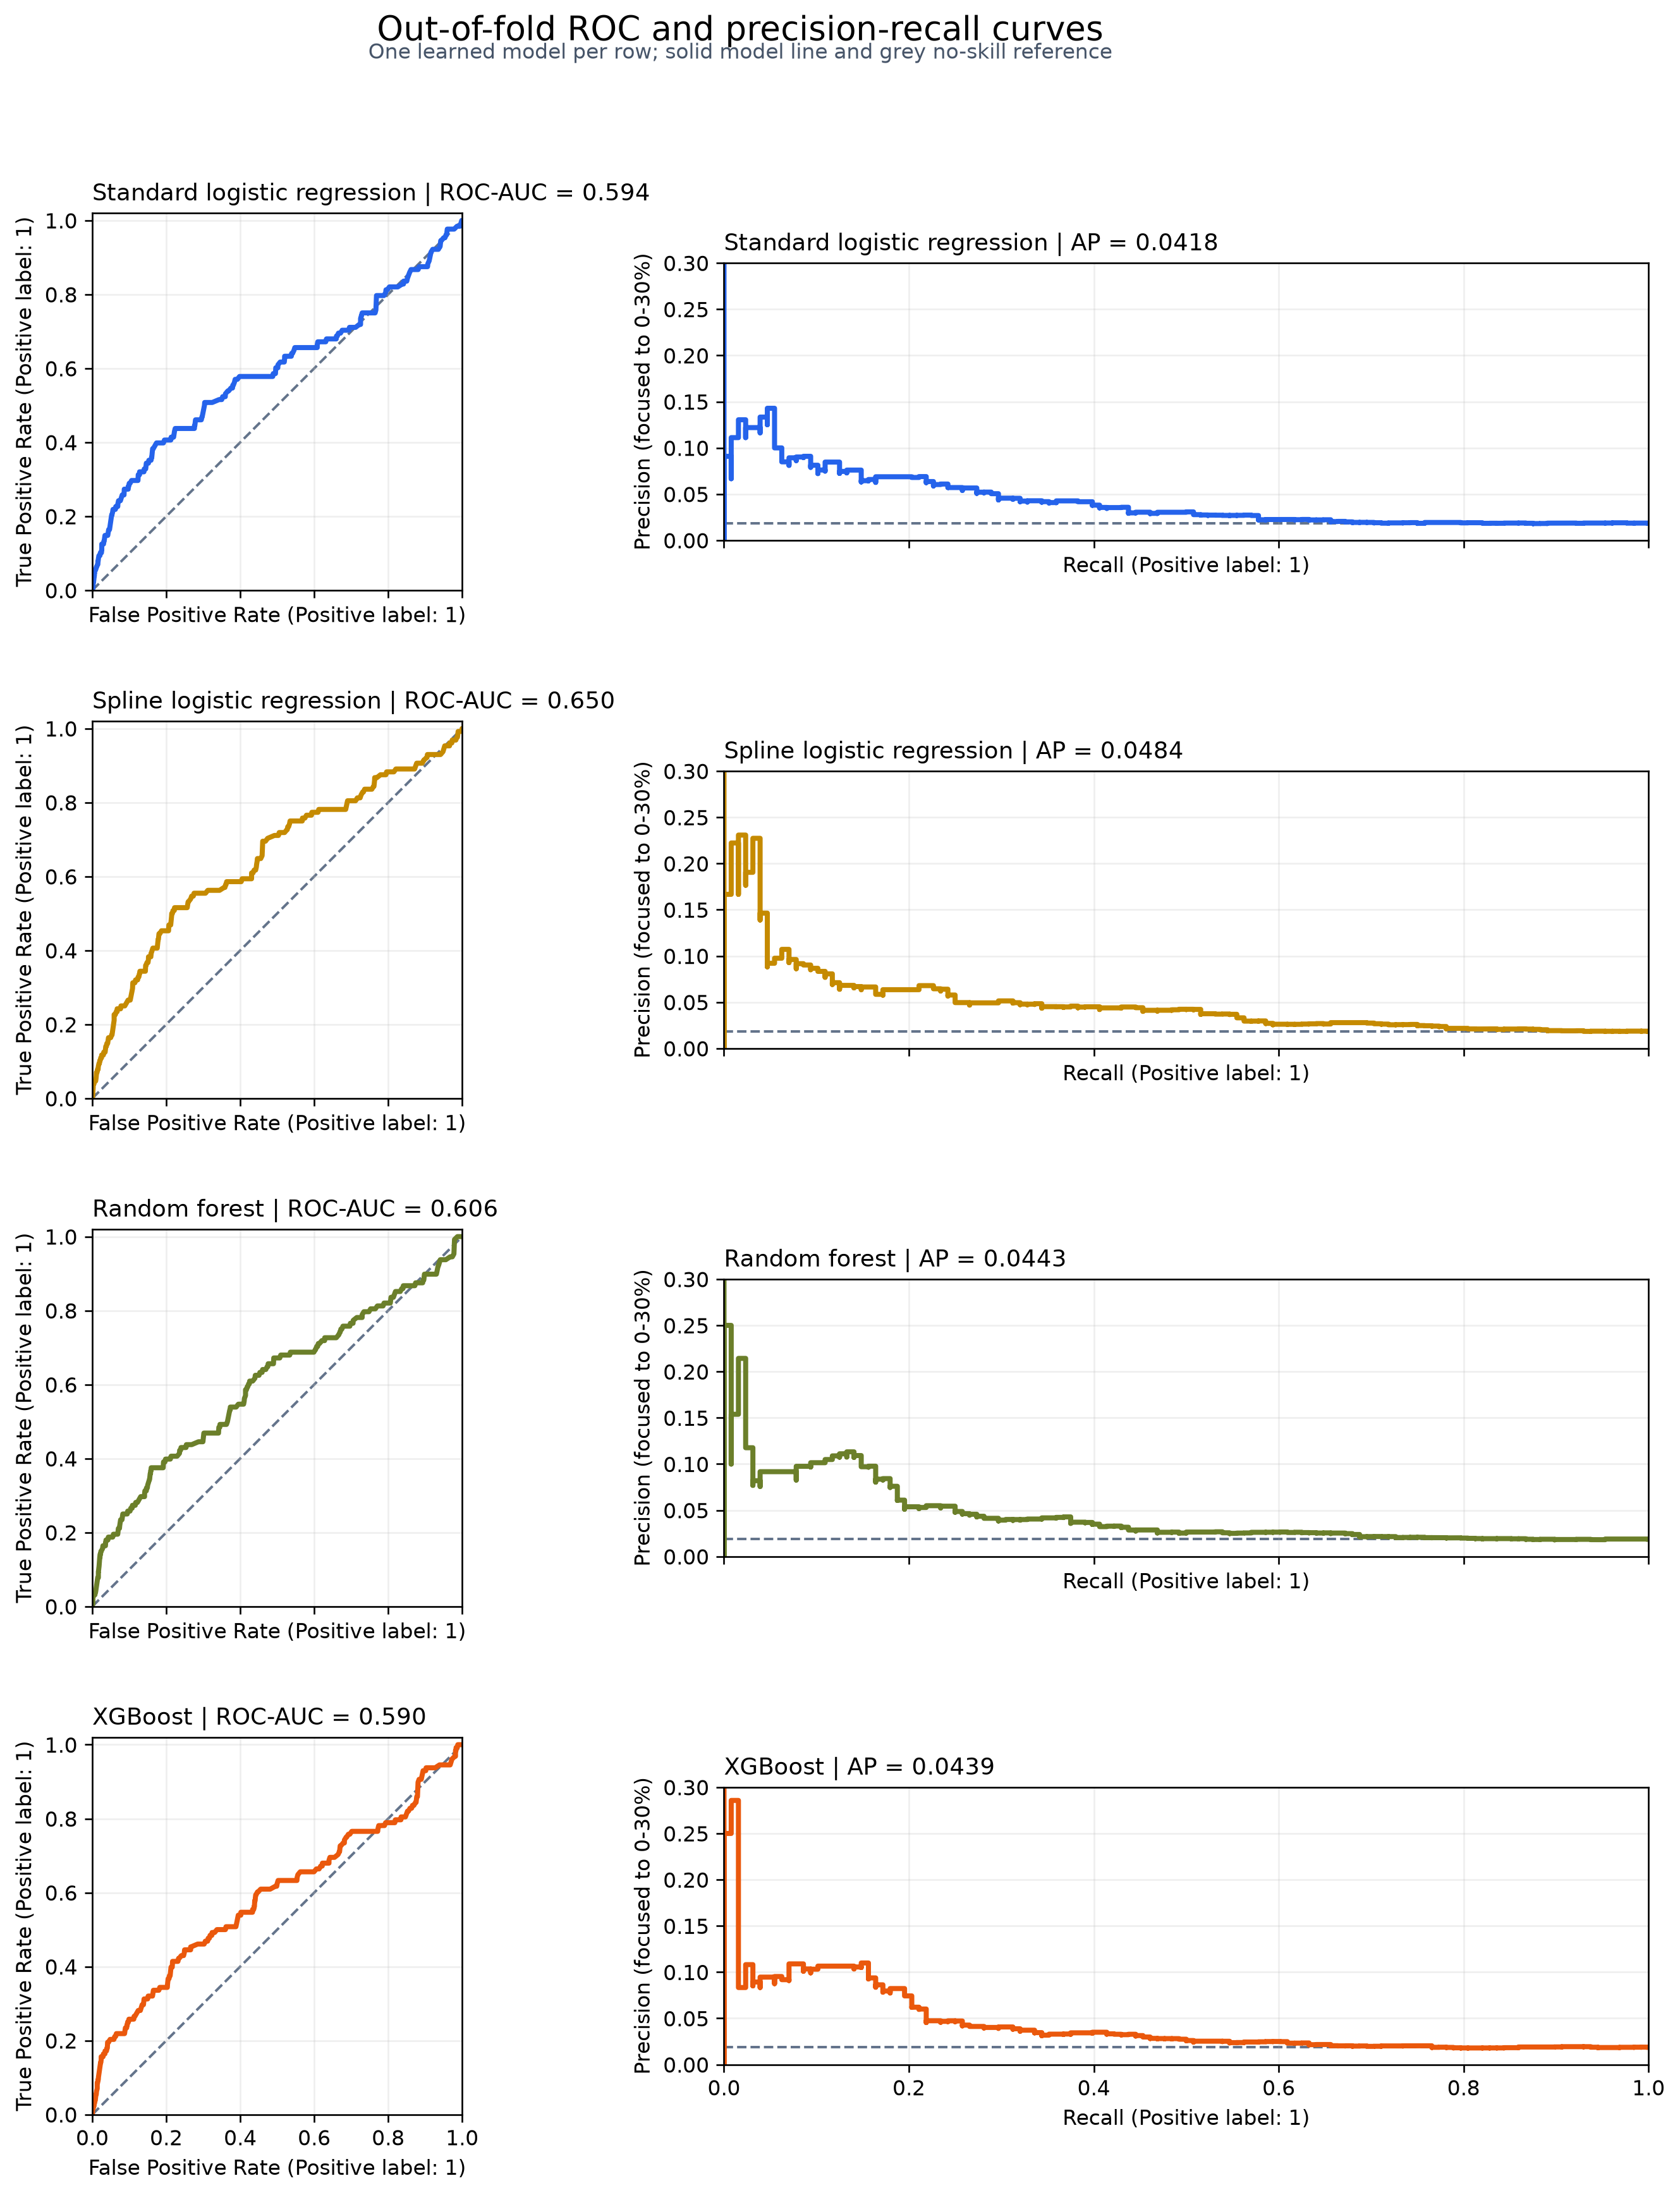

In [8]:
COLORS = {
    "logistic": "#2563EB",
    "spline_logistic": "#C58A00",
    "random_forest": "#6B7F2A",
    "xgboost": "#EA580C",
}

learned_model_names = [
    "logistic",
    "spline_logistic",
    "random_forest",
    "xgboost",
]
fig, axes = plt.subplots(
    len(learned_model_names),
    2,
    figsize=(12.5, 14.5),
    sharex="col",
    sharey="col",
)

for row, model_name in enumerate(learned_model_names):
    probability_column = f"{model_name}_probability"
    model_label = MODEL_LABELS[model_name]
    model_color = COLORS[model_name]
    roc_axis, precision_recall_axis = axes[row]

    RocCurveDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=model_label,
        curve_kwargs={
            "color": model_color,
            "linestyle": "-",
            "linewidth": 2.4,
        },
        ax=roc_axis,
    )
    roc_axis.plot(
        [0, 1],
        [0, 1],
        color="#64748B",
        linestyle="--",
        linewidth=1.2,
        zorder=0,
    )
    roc_axis.set_title(
        f"{model_label} | ROC-AUC = "
        f"{overall_metrics.loc[model_label, 'roc_auc']:.3f}",
        loc="left",
        fontsize=11,
    )
    roc_axis.set_xlim(0, 1)
    roc_axis.set_ylim(0, 1.02)

    PrecisionRecallDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=model_label,
        curve_kwargs={
            "color": model_color,
            "linestyle": "-",
            "linewidth": 2.4,
        },
        ax=precision_recall_axis,
    )
    precision_recall_axis.axhline(
        train["target"].mean(),
        color="#64748B",
        linestyle="--",
        linewidth=1.2,
        zorder=0,
    )
    precision_recall_axis.set_title(
        f"{model_label} | AP = "
        f"{overall_metrics.loc[model_label, 'average_precision']:.4f}",
        loc="left",
        fontsize=11,
    )
    precision_recall_axis.set_xlim(0, 1)
    precision_recall_axis.set_ylim(0, 0.30)
    precision_recall_axis.set_ylabel("Precision (focused to 0-30%)")

    for axis in (roc_axis, precision_recall_axis):
        legend = axis.get_legend()
        if legend is not None:
            legend.remove()
        axis.grid(alpha=0.20)

fig.suptitle(
    "Out-of-fold ROC and precision-recall curves",
    fontsize=16,
    y=0.995,
)
fig.text(
    0.5,
    0.975,
    "One learned model per row; solid model line and grey no-skill reference",
    ha="center",
    fontsize=10,
    color="#475569",
)
fig.tight_layout(rect=[0, 0, 1, 0.955], h_pad=3.0, w_pad=2.0)

CURVES_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(CURVES_PATH, dpi=320, bbox_inches="tight")
plt.show()


### 5. Feature ablation: identify where the signal comes from

Feature ablation refits the **same spline-logistic model** with different predictor sets. Because the model and patient-safe folds stay fixed, changes in performance show what information is added by age, sex, and anatomical site.

This is predictive contribution, not causation. Small differences may be sampling noise and should eventually be checked with patient-level confidence intervals.


,Features,roc_auc,average_precision,AP gain vs dummy,log_loss,brier_score
Feature set,,,,,,
Sex only,sex,0.5227,0.0196,0.0012,0.0926,0.0183
Age only,age_approx,0.6304,0.0410,0.0226,0.0902,0.0182
Site only,anatom_site_general_challenge,0.5476,0.0264,0.0080,0.0916,0.0182
Sex + age,"sex, age_approx",0.6205,0.0402,0.0217,0.0905,0.0182
Sex + site,"sex, anatom_site_general_challenge",0.5798,0.0292,0.0108,0.0915,0.0182
Age + site,"age_approx, anatom_site_general_challenge",0.6553,0.0479,0.0295,0.0895,0.0181
All features,"sex, age_approx, anatom_site_general_challenge",0.6499,0.0484,0.0299,0.0897,0.0181


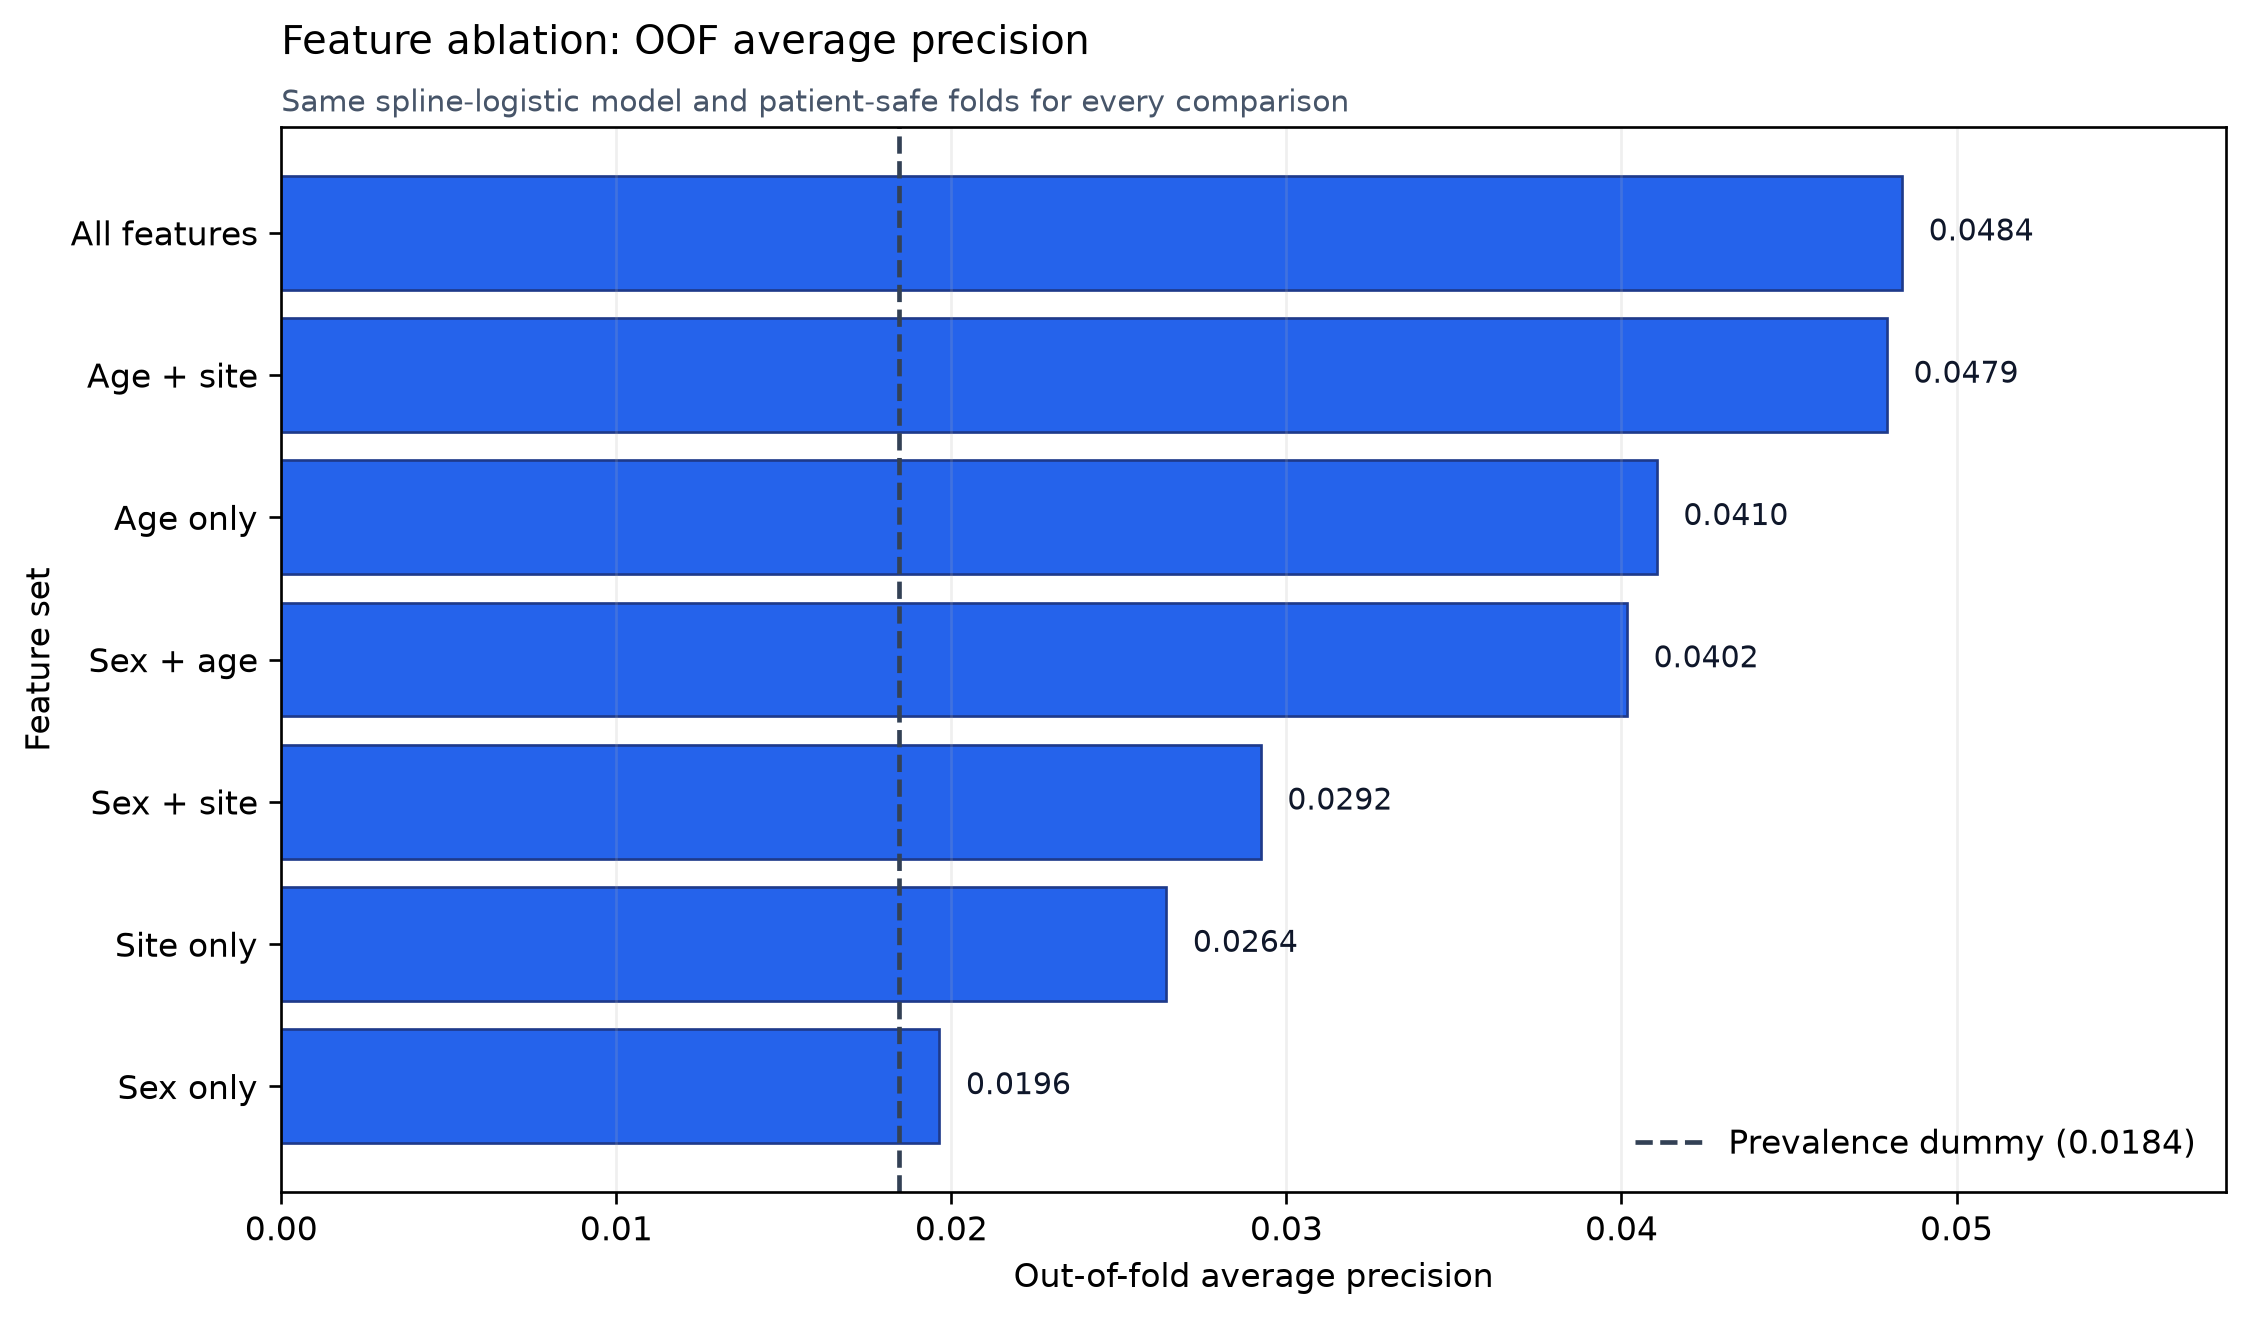

In [9]:
ablation_feature_sets = {
    "Sex only": ["sex"],
    "Age only": ["age_approx"],
    "Site only": ["anatom_site_general_challenge"],
    "Sex + age": ["sex", "age_approx"],
    "Sex + site": ["sex", "anatom_site_general_challenge"],
    "Age + site": ["age_approx", "anatom_site_general_challenge"],
    "All features": FEATURE_COLUMNS,
}

ablation_rows = []
full_feature_ablation_probabilities = None
for feature_set_name, feature_set_columns in ablation_feature_sets.items():
    ablation_model = make_metadata_pipeline(
        logistic_regression(), feature_set_columns, smooth_age=True
    )
    ablation_probabilities = generate_oof_probabilities(
        train, ablation_model, feature_set_columns
    )
    ablation_metrics = binary_probability_metrics(
        train["target"],
        ablation_probabilities,
    )
    ablation_rows.append(
        {
            "Feature set": feature_set_name,
            "Features": ", ".join(feature_set_columns),
            **ablation_metrics,
        }
    )
    if feature_set_name == "All features":
        full_feature_ablation_probabilities = ablation_probabilities

assert np.allclose(
    full_feature_ablation_probabilities,
    oof_predictions["spline_logistic_probability"],
)

ablation_results = pd.DataFrame(ablation_rows).set_index("Feature set")
dummy_average_precision = overall_metrics.loc["Prevalence dummy", "average_precision"]
ablation_results["AP gain vs dummy"] = (
    ablation_results["average_precision"] - dummy_average_precision
)

display(
    ablation_results[
        ["Features", "roc_auc", "average_precision", "AP gain vs dummy", "log_loss", "brier_score"]
    ].round(4)
)

plot_data = ablation_results.sort_values("average_precision")
fig, axis = plt.subplots(figsize=(9.5, 5.6))
bars = axis.barh(
    plot_data.index,
    plot_data["average_precision"],
    color="#2563EB",
    edgecolor="#1E3A8A",
    linewidth=0.8,
)
axis.axvline(
    dummy_average_precision,
    color="#334155",
    linestyle="--",
    linewidth=1.4,
    label=f"Prevalence dummy ({dummy_average_precision:.4f})",
)

for bar, value in zip(bars, plot_data["average_precision"]):
    axis.text(
        value + 0.0008,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=9,
        color="#0F172A",
    )

axis.set_xlim(0, plot_data["average_precision"].max() * 1.20)
axis.set_xlabel("Out-of-fold average precision")
axis.set_ylabel("Feature set")
axis.set_title("Feature ablation: OOF average precision", loc="left", pad=22)
axis.text(
    0,
    1.015,
    "Same spline-logistic model and patient-safe folds for every comparison",
    transform=axis.transAxes,
    fontsize=9,
    color="#475569",
)
axis.legend(frameon=False, loc="lower right")
axis.grid(axis="x", alpha=0.20)
fig.tight_layout()
plt.show()

**Feature-ablation interpretation**

- Sex alone is close to the prevalence baseline: AP increases only from 0.0184 to 0.0196.
- Age supplies the strongest individual signal, reaching 0.0410 AP.
- Anatomical site alone reaches 0.0264 AP and adds useful information when combined with age.
- Age plus site reaches 0.0479 AP. Adding sex raises AP only slightly to 0.0484 and lowers ROC-AUC from 0.655 to 0.650.

The practical conclusion is that **age and anatomical site contain nearly all of the useful metadata signal** in this subset. The tiny change from adding sex should not be treated as a reliable improvement without uncertainty intervals.


### 6. Interpret the spline age relationship

Spline coefficients belong to mathematical basis functions and are not meaningful on their own. A clearer interpretation is to plot the model-implied average risk at each age while averaging over the observed sex and site distribution.

The model is fitted to all development rows only for this descriptive plot. Predictive performance still comes from the OOF results above.


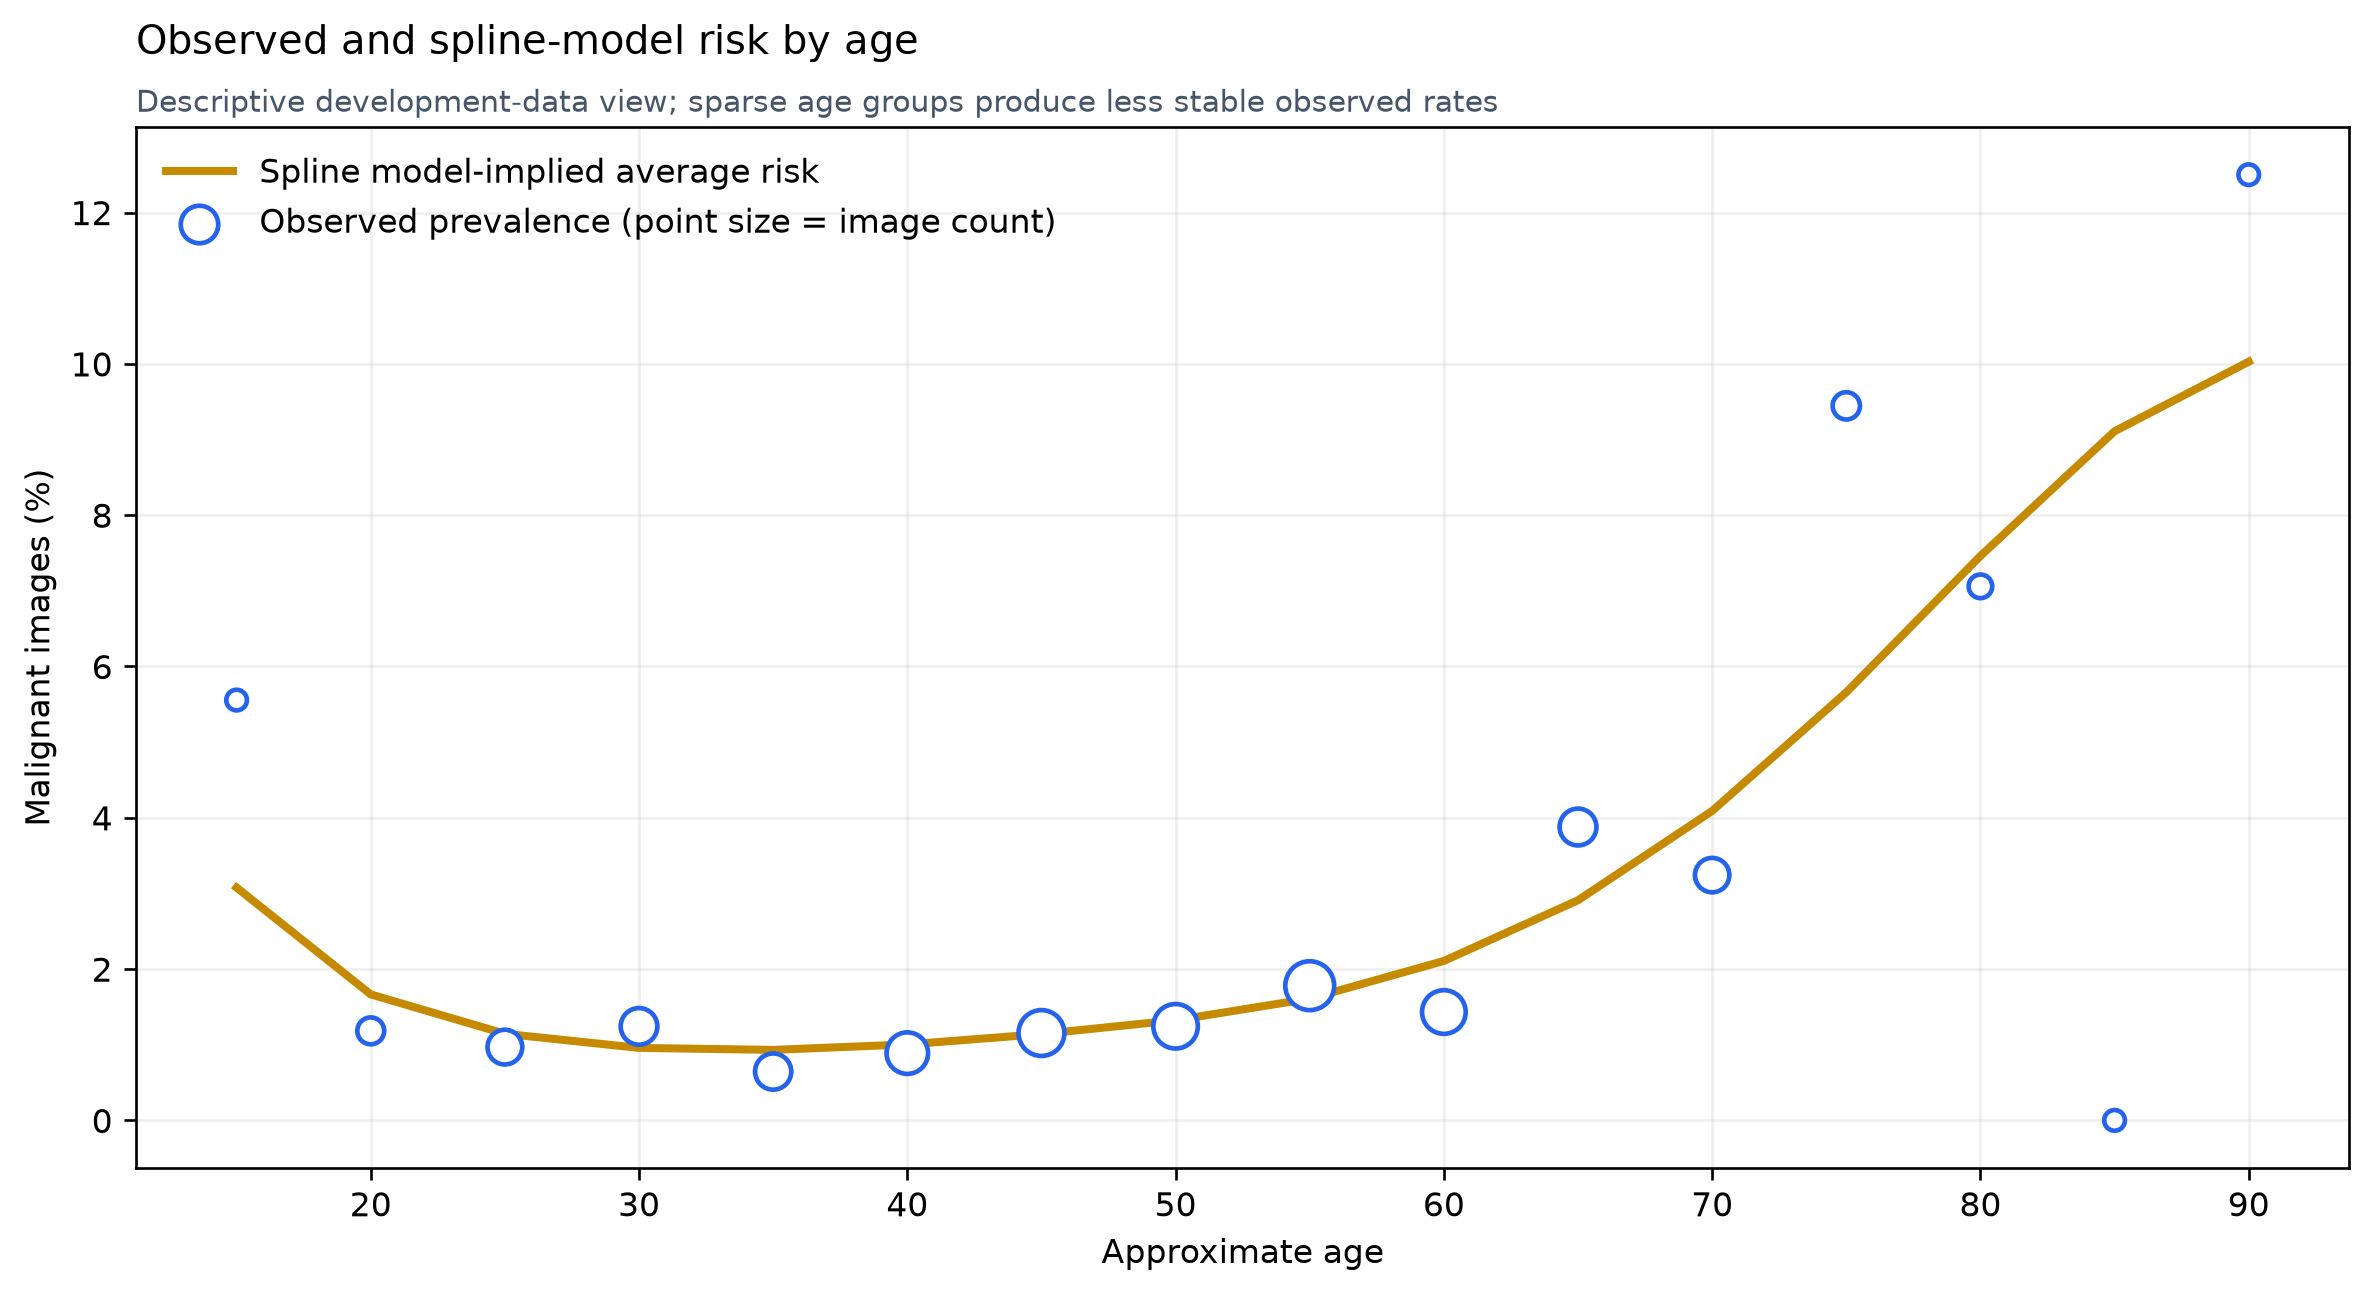

,age,images,malignant_images,Observed prevalence (%),Model-implied average risk (%)
0,15,18,1,5.56,3.08
1,20,169,2,1.18,1.67
2,25,413,4,0.97,1.14
3,30,483,6,1.24,0.96
4,35,465,3,0.65,0.93
5,40,675,6,0.89,1.00
6,45,866,10,1.15,1.14
7,50,804,10,1.24,1.32
8,55,1011,18,1.78,1.61
9,60,768,11,1.43,2.11


In [10]:
fitted_spline_model = make_metadata_pipeline(
    logistic_regression(), FEATURE_COLUMNS, smooth_age=True
)
fitted_spline_model.fit(train[FEATURE_COLUMNS], train["target"])

age_values = sorted(pd.to_numeric(train["age_approx"], errors="coerce").dropna().unique())
marginal_age_rows = []
for age in age_values:
    age_scenario = train[FEATURE_COLUMNS].copy()
    age_scenario["age_approx"] = str(int(age))
    marginal_age_rows.append(
        {
            "age": int(age),
            "model_implied_average_risk": fitted_spline_model.predict_proba(age_scenario)[:, 1].mean(),
        }
    )

marginal_age_risk = pd.DataFrame(marginal_age_rows)
observed_age_risk = (
    train.assign(age=pd.to_numeric(train["age_approx"], errors="coerce"))
    .groupby("age", as_index=False)["target"]
    .agg(images="size", malignant_images="sum", observed_prevalence="mean")
)
age_interpretation = observed_age_risk.merge(marginal_age_risk, on="age", how="left")

fig, axis = plt.subplots(figsize=(10, 5.5))
axis.plot(
    age_interpretation["age"],
    age_interpretation["model_implied_average_risk"] * 100,
    color="#C58A00",
    linewidth=2.4,
    label="Spline model-implied average risk",
)
marker_sizes = 35 + 180 * age_interpretation["images"] / age_interpretation["images"].max()
axis.scatter(
    age_interpretation["age"],
    age_interpretation["observed_prevalence"] * 100,
    s=marker_sizes,
    facecolors="white",
    edgecolors="#2563EB",
    linewidths=1.4,
    label="Observed prevalence (point size = image count)",
    zorder=3,
)
axis.set_xlabel("Approximate age")
axis.set_ylabel("Malignant images (%)")
axis.set_title("Observed and spline-model risk by age", loc="left", pad=22)
axis.text(
    0,
    1.015,
    "Descriptive development-data view; sparse age groups produce less stable observed rates",
    transform=axis.transAxes,
    fontsize=9,
    color="#475569",
)
axis.grid(alpha=0.20)
axis.legend(frameon=False)
fig.tight_layout()
plt.show()

display(
    age_interpretation.assign(
        **{
            "Observed prevalence (%)": age_interpretation["observed_prevalence"] * 100,
            "Model-implied average risk (%)": age_interpretation["model_implied_average_risk"] * 100,
        }
    )[
        ["age", "images", "malignant_images", "Observed prevalence (%)", "Model-implied average risk (%)"]
    ].round(2)
)

The observed points fluctuate sharply at ages with very few images. The spline deliberately smooths those jumps and shows the broader predictive pattern: estimated metadata risk generally rises at older ages. This remains an association within the development data, not evidence that age causes melanoma.


### 7. Describe raw prevalence by sex and anatomical site

In [11]:
def prevalence_by_category(frame, column, feature_label):
    summary = (
        frame.groupby(column, dropna=False)["target"]
        .agg(images="size", malignant_images="sum", prevalence="mean")
        .reset_index()
        .rename(columns={column: "Category"})
    )
    summary.insert(0, "Feature", feature_label)
    summary["Prevalence (%)"] = summary.pop("prevalence") * 100
    return summary.sort_values("Prevalence (%)", ascending=False)


category_prevalence = pd.concat(
    [
        prevalence_by_category(train, "sex", "Sex"),
        prevalence_by_category(
            train,
            "anatom_site_general_challenge",
            "Anatomical site",
        ),
    ],
    ignore_index=True,
)
category_prevalence.round({"Prevalence (%)": 2})

,Feature,Category,images,malignant_images,Prevalence (%)
0,Sex,male,3311,75,2.27
1,Sex,female,3553,53,1.49
2,Anatomical site,oral/genital,33,3,9.09
3,Anatomical site,head/neck,409,21,5.13
4,Anatomical site,upper extremity,1066,23,2.16
5,Anatomical site,torso,3440,54,1.57
6,Anatomical site,lower extremity,1650,25,1.52
7,Anatomical site,Unknown,196,2,1.02
8,Anatomical site,palms/soles,70,0,0.00


These are unadjusted descriptive rates. Categories with few images or malignant cases, such as oral/genital and palms/soles, can show extreme percentages by chance and should not be ranked as if their estimates were equally reliable.


### 8. Select exploratory thresholds for confusion matrices

At the conventional 0.50 probability cutoff, all five models classify every image as benign in this run. That cutoff is not informative when predicted probabilities are concentrated near the 1.86% prevalence.

For a descriptive comparison, a separate threshold is selected for each learned model by maximizing balanced accuracy on its OOF predictions. The prevalence dummy remains fixed at 0.50 because it has no meaningful within-fold ranking information.

Because threshold selection and assessment use the same OOF labels, the resulting matrices describe possible sensitivity and specificity trade-offs. They are not final-test or clinically validated results.


In [12]:
def select_balanced_accuracy_threshold(y_true, probabilities):
    candidates = np.unique(np.concatenate(([0.0], probabilities, [1.0])))
    scores = np.array(
        [
            balanced_accuracy_score(y_true, probabilities >= threshold)
            for threshold in candidates
        ]
    )
    best_indices = np.flatnonzero(np.isclose(scores, scores.max()))
    best_index = best_indices[np.argmin(np.abs(candidates[best_indices] - 0.50))]
    return float(candidates[best_index]), float(scores[best_index])


y_true = oof_predictions["target"].to_numpy()
selected_thresholds = {"dummy": 0.50}
threshold_rows = []
default_threshold_rows = []

for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()

    default_tn, default_fp, default_fn, default_tp = confusion_matrix(
        y_true,
        probabilities >= 0.50,
        labels=[0, 1],
    ).ravel()
    default_threshold_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": 0.50,
            "TN": default_tn,
            "FP": default_fp,
            "FN": default_fn,
            "TP": default_tp,
        }
    )

    if model_name == "dummy":
        threshold = 0.50
        balanced_accuracy = balanced_accuracy_score(y_true, probabilities >= threshold)
        threshold_type = "Fixed"
    else:
        threshold, balanced_accuracy = select_balanced_accuracy_threshold(
            y_true,
            probabilities,
        )
        selected_thresholds[model_name] = threshold
        threshold_type = "Exploratory OOF-selected"

    threshold_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "Threshold type": threshold_type,
            "Balanced accuracy": balanced_accuracy,
        }
    )

print("Default 0.50 threshold results:")
display(pd.DataFrame(default_threshold_rows).set_index("Model"))

threshold_summary = pd.DataFrame(threshold_rows).set_index("Model")
threshold_summary.round({"Threshold": 4, "Balanced accuracy": 4})

Default 0.50 threshold results:


,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6736,0,128,0
Standard logistic regression,0.5,6736,0,128,0
Spline logistic regression,0.5,6736,0,128,0
Random forest,0.5,6736,0,128,0
XGBoost,0.5,6736,0,128,0


,Threshold,Threshold type,Balanced accuracy
Model,,,
Prevalence dummy,0.5000,Fixed,0.5000
Standard logistic regression,0.0273,Exploratory OOF-selected,0.6124
Spline logistic regression,0.0225,Exploratory OOF-selected,0.6466
Random forest,0.0258,Exploratory OOF-selected,0.6079
XGBoost,0.0234,Exploratory OOF-selected,0.5985


### 9. Compare TN, FP, FN, and TP as counts and percentages

Percentages are normalized within each actual class:

- TN and FP percentages add to 100% of actual benign images.
- FN and TP percentages add to 100% of actual malignant images.


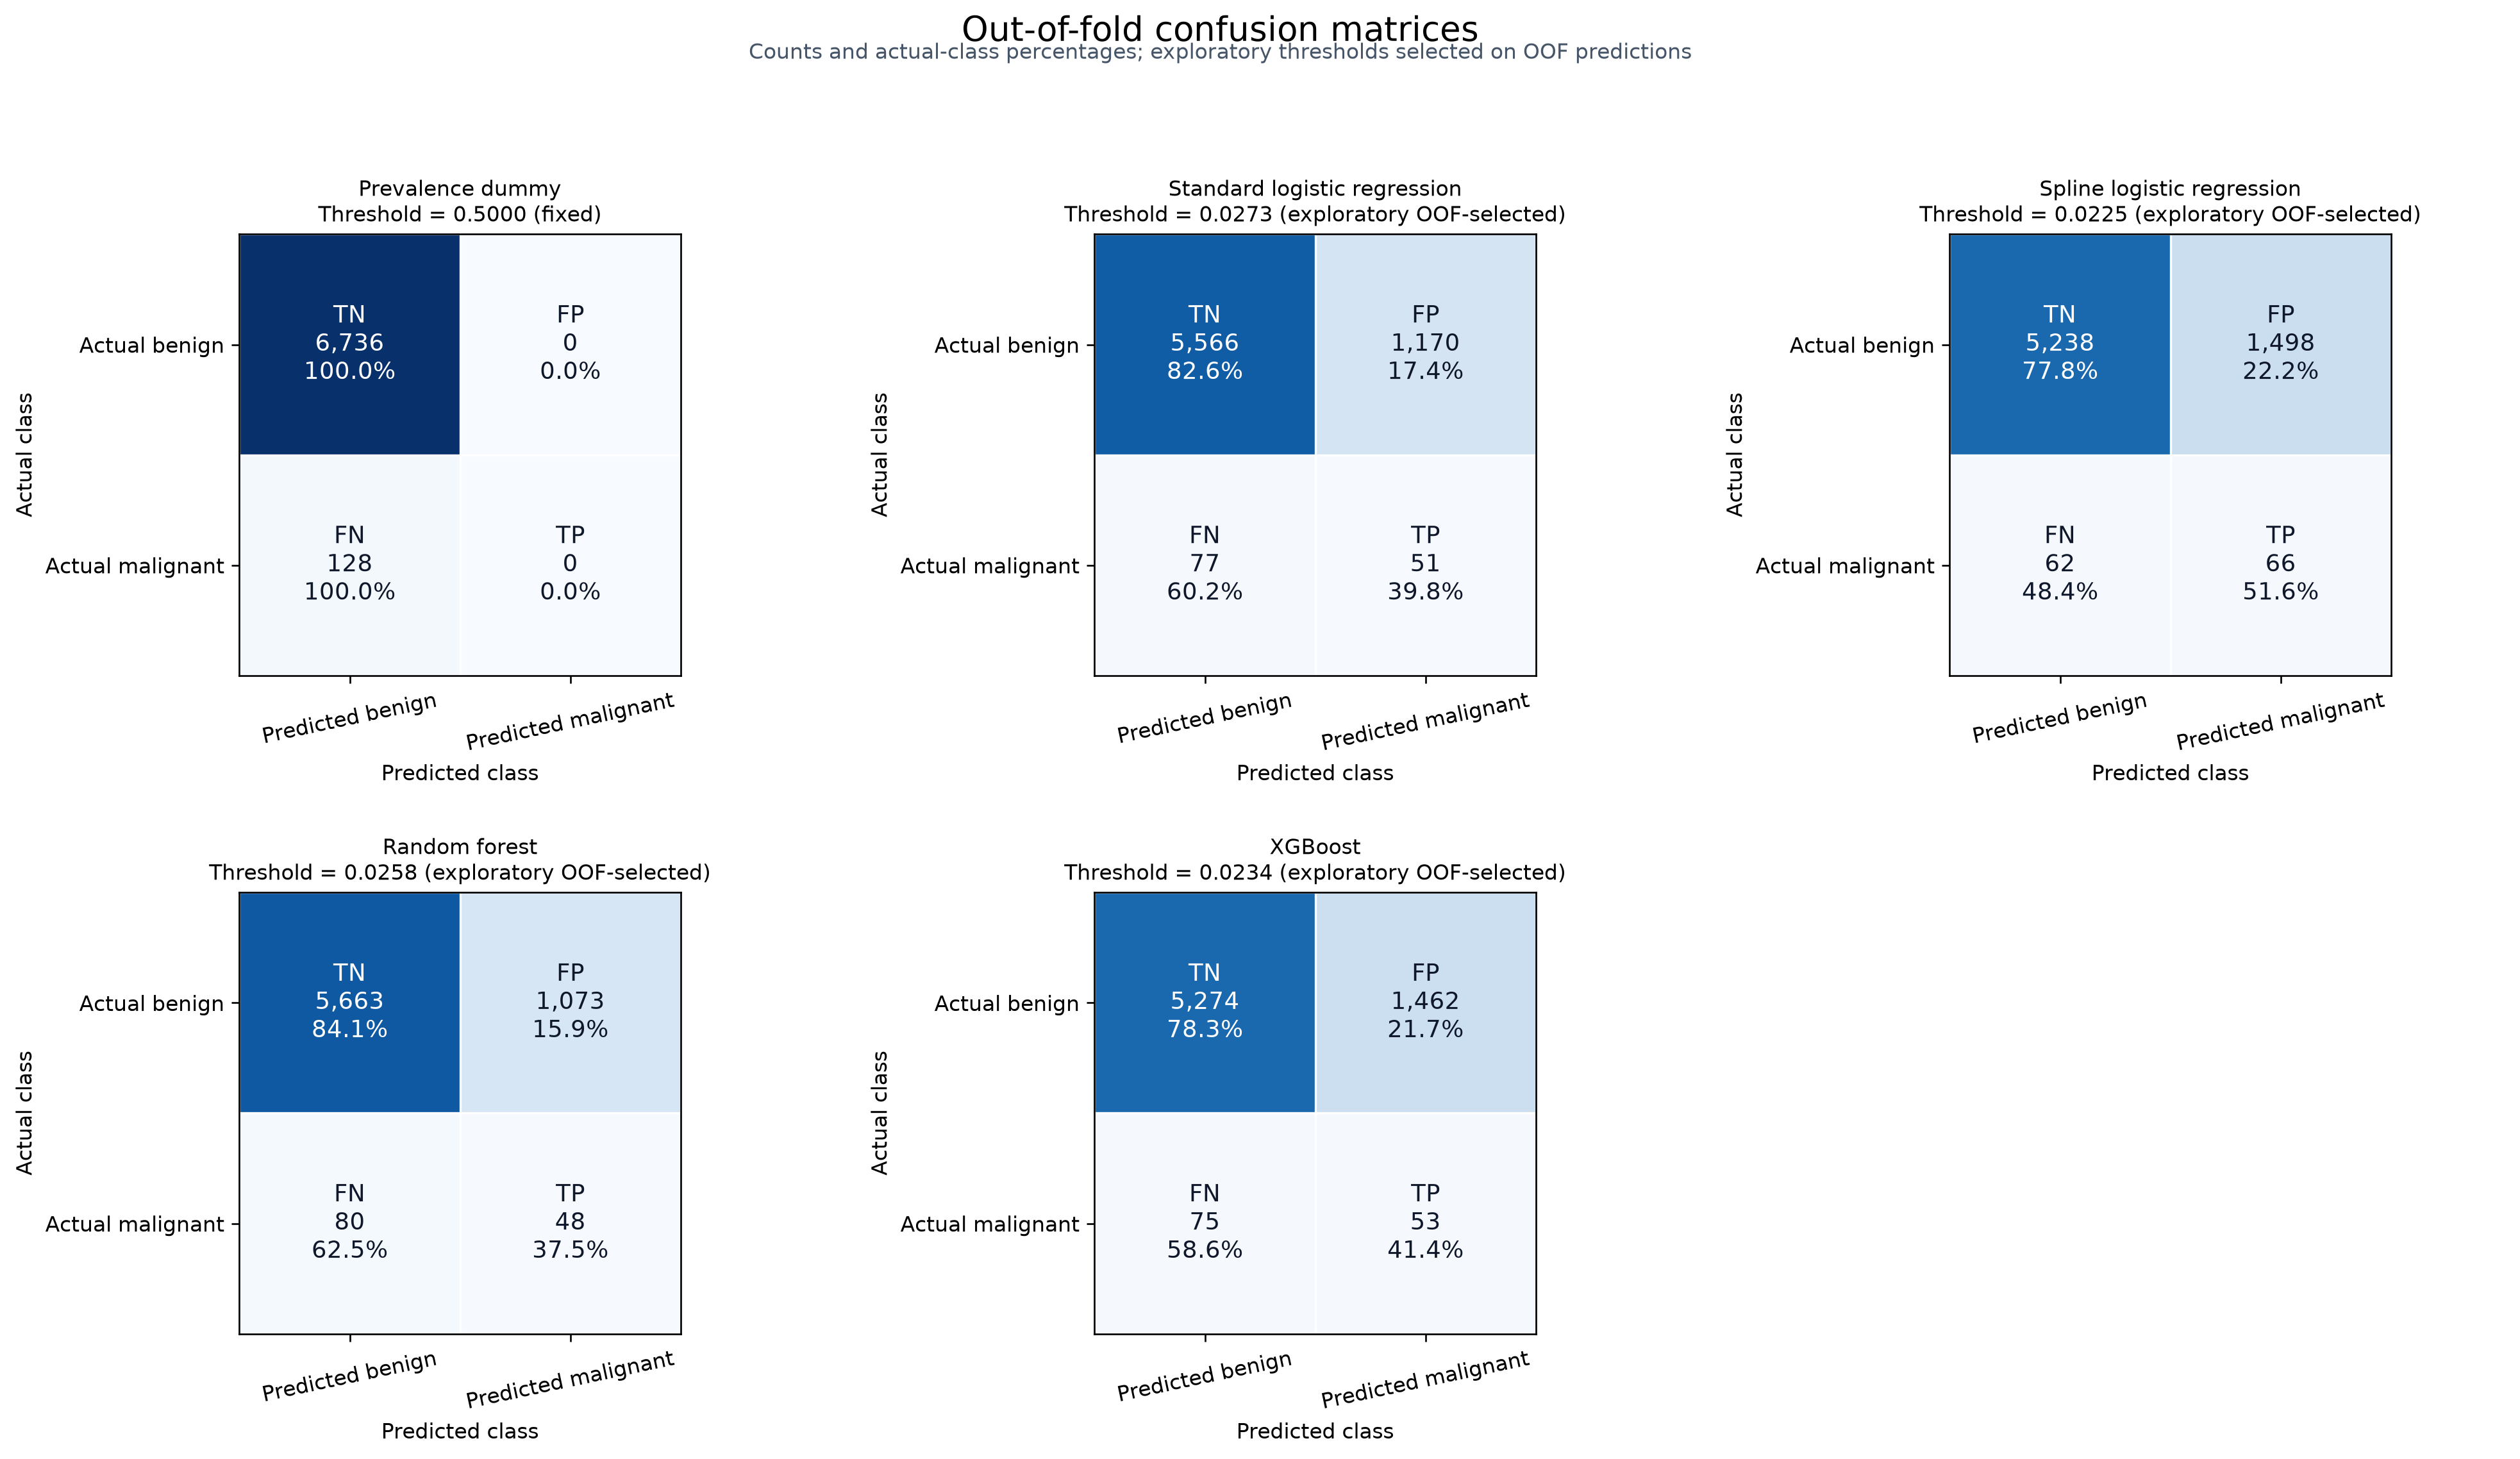

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6736,100.0,0,0.0,128,100.0,0,0.0,0.0
Standard logistic regression,0.0273,5566,82.6,1170,17.4,77,60.2,51,39.8,4.2
Spline logistic regression,0.0225,5238,77.8,1498,22.2,62,48.4,66,51.6,4.2
Random forest,0.0258,5663,84.1,1073,15.9,80,62.5,48,37.5,4.3
XGBoost,0.0234,5274,78.3,1462,21.7,75,58.6,53,41.4,3.5


In [13]:
confusion_matrices = {}
for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    predicted_labels = (probabilities >= selected_thresholds[model_name]).astype(int)
    confusion_matrices[model_name] = confusion_matrix(
        y_true,
        predicted_labels,
        labels=[0, 1],
    )

shared_maximum = max(matrix.max() for matrix in confusion_matrices.values())
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
confusion_rows = []

for axis, model_name in zip(axes.flat, estimators):
    threshold = selected_thresholds[model_name]
    matrix = confusion_matrices[model_name]
    tn, fp, fn, tp = matrix.ravel()
    row_percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100

    annotations = np.array(
        [
            [
                f"TN\n{tn:,}\n{row_percentages[0, 0]:.1f}%",
                f"FP\n{fp:,}\n{row_percentages[0, 1]:.1f}%",
            ],
            [
                f"FN\n{fn:,}\n{row_percentages[1, 0]:.1f}%",
                f"TP\n{tp:,}\n{row_percentages[1, 1]:.1f}%",
            ],
        ]
    )

    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=shared_maximum)
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > shared_maximum / 2 else "#0F172A"
            axis.text(
                column,
                row,
                annotations[row, column],
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
            )

    axis.set_xticks([0, 1], labels=["Predicted benign", "Predicted malignant"])
    axis.set_yticks([0, 1], labels=["Actual benign", "Actual malignant"])
    axis.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    axis.grid(which="minor", color="white", linestyle="-", linewidth=1)
    axis.tick_params(which="minor", bottom=False, left=False)
    threshold_description = "fixed" if model_name == "dummy" else "exploratory OOF-selected"
    axis.set_title(
        f"{MODEL_LABELS[model_name]}\nThreshold = {threshold:.4f} ({threshold_description})",
        fontsize=10,
    )
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=12)

    confusion_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "TN": tn,
            "TN % of actual benign": row_percentages[0, 0],
            "FP": fp,
            "FP % of actual benign": row_percentages[0, 1],
            "FN": fn,
            "FN % of actual malignant": row_percentages[1, 0],
            "TP": tp,
            "TP % of actual malignant": row_percentages[1, 1],
            "Precision among predicted malignant (%)": (
                tp / (tp + fp) * 100 if (tp + fp) else 0.0
            ),
        }
    )

for unused_axis in axes.flat[len(estimators):]:
    unused_axis.axis("off")

fig.suptitle("Out-of-fold confusion matrices", fontsize=16, y=0.995)
fig.text(
    0.5,
    0.965,
    "Counts and actual-class percentages; exploratory thresholds selected on OOF predictions",
    ha="center",
    fontsize=10,
    color="#475569",
)
fig.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.2, w_pad=1.8)
plt.show()

confusion_results = pd.DataFrame(confusion_rows).set_index("Model")
confusion_results.round(
    {
        "Threshold": 4,
        "TN % of actual benign": 1,
        "FP % of actual benign": 1,
        "FN % of actual malignant": 1,
        "TP % of actual malignant": 1,
        "Precision among predicted malignant (%)": 1,
    }
)

## Recommended next metadata analyses

The spline model and feature ablation clarify the main predictive pattern. The next useful work is to test whether that pattern is reliable and operationally useful, rather than adding more model families.

1. **Patient-bootstrap uncertainty:** calculate confidence intervals for AP, ROC-AUC, and the differences between models by resampling whole patients.
2. **Calibration curves:** compare predicted probability with observed malignancy frequency using a small number of quantile bins.
3. **Risk-ranking analysis:** show how many malignant images are found when reviewing the highest-risk 5%, 10%, or 20% of images.
4. **Subgroup error analysis:** compare sensitivity and false-positive rates by broad age band, sex, and site, always displaying malignant-case counts.
5. **Secondary patient-level view:** aggregate each patient's OOF image probabilities and evaluate whether the patient has any malignant lesion. Keep this secondary to the image-level task.


## Takeaways

1. The prevalence dummy establishes the no-skill reference at **0.0184 AP**.
2. Standard logistic regression reaches **0.594 ROC-AUC** and **0.0418 AP**.
3. Spline logistic regression performs best overall at **0.650 ROC-AUC** and **0.0484 AP**. Its smooth age term extracts more useful structure than independent five-year age categories.
4. Feature ablation identifies age as the main metadata signal. Age plus site reaches **0.0479 AP**; adding sex changes AP only slightly to **0.0484**.
5. Random forest and XGBoost remain useful nonlinear comparisons, but neither surpasses the spline model on pooled OOF ROC-AUC or AP.
6. At its exploratory threshold of **0.0225**, the spline model detects **66/128 malignant images (51.6%)** and incorrectly flags **1,498/6,736 benign images (22.2%)**. This is a descriptive trade-off, not a final clinical threshold.
7. The metadata signal is real but limited: even the best model has low precision because malignant images are extremely rare and metadata does not describe lesion appearance.
8. The labelled test subset remains untouched. Final evaluation should occur only after the modelling and threshold choices are frozen.
